In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, roc_auc_score

# 1. Load Dataset
DATA_PATH = Path("c:/Users/danya/OneDrive/Desktop/Smart_Gradient_Analytics/Data/processed/Cleaned.parquet")
if not DATA_PATH.exists():
    DATA_PATH = Path("Cleaned.parquet")

df = pd.read_parquet(DATA_PATH)
# Resample to hourly mean for high signal-to-noise ratio and fast execution, dropping long outages
df_hr = df.resample("h").mean().dropna().copy()
print("Loaded hourly shape:", df_hr.shape)
df_hr.head(3)

Loaded hourly shape: (34168, 8)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour
DateTime,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19.0


In [3]:
# 2. Inject Realistic Synthetic Anomalies 
np.random.seed(42)
data = df_hr.copy()
n = len(data)
anomaly_rate = 0.02
n_anomalies = int(n * anomaly_rate)

data["is_anomaly"] = 0
anomaly_indices = np.random.choice(np.arange(24, n - 24), size=n_anomalies, replace=False)

for idx in anomaly_indices:
    kind = np.random.choice(["spike", "drop", "voltage_sag"])
    if kind == "spike":
        # Sudden surge in active power & intensity
        factor = np.random.uniform(3.0, 4.5)
        data.iloc[idx, data.columns.get_loc("Global_active_power")] *= factor
        data.iloc[idx, data.columns.get_loc("Global_intensity")] *= factor
    elif kind == "drop":
        # Near-zero consumption drop during active hours
        data.iloc[idx, data.columns.get_loc("Global_active_power")] *= 0.05
        data.iloc[idx, data.columns.get_loc("Global_intensity")] *= 0.05
    else:
        # Grid voltage sag with elevated reactive power
        data.iloc[idx, data.columns.get_loc("Voltage")] -= np.random.uniform(15, 25)
        data.iloc[idx, data.columns.get_loc("Global_reactive_power")] *= 3.0
    data.iloc[idx, data.columns.get_loc("is_anomaly")] = 1

print(f"Injected {data['is_anomaly'].sum()} anomalies ({data['is_anomaly'].mean():.2%})")

Injected 683 anomalies (2.00%)


In [4]:
# 3. Feature Engineering
fe = pd.DataFrame(index=data.index)

# Core electrical measurements (dropping Global_intensity due to >0.99 collinearity with Global_active_power)
base_cols = ["Global_active_power", "Global_reactive_power", "Voltage", 
             "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
for col in base_cols:
    fe[col] = data[col]

# Cyclical time features
fe["hour_sin"] = np.sin(2 * np.pi * data.index.hour / 24.0)
fe["hour_cos"] = np.cos(2 * np.pi * data.index.hour / 24.0)
fe["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

# Rolling context & deviation features (24-hour window)
roll_mean = data["Global_active_power"].rolling(24, min_periods=1).mean()
roll_std = data["Global_active_power"].rolling(24, min_periods=1).std().fillna(1e-5)
fe["power_zscore_24h"] = (data["Global_active_power"] - roll_mean) / (roll_std + 1e-5)
fe["power_diff_1h"] = data["Global_active_power"].diff().fillna(0)
fe["voltage_diff_1h"] = data["Voltage"].diff().fillna(0)
fe["power_factor"] = data["Global_active_power"] / np.sqrt(
    data["Global_active_power"]**2 + data["Global_reactive_power"]**2 + 1e-5
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(fe)
y_true = data["is_anomaly"].values
print("Engineered feature matrix shape:", X_scaled.shape)

Engineered feature matrix shape: (34168, 13)


C:\Users\danya\AppData\Local\Temp\ipykernel_16332\1287483722.py:13: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  fe["is_weekend"] = (data.index.dayofweek >= 5).astype(int)


In [5]:
# 4. Train & Evaluate Two Best-Suited Unsupervised Models
# Model 1: Isolation Forest
iso = IsolationForest(n_estimators=200, contamination=anomaly_rate, random_state=42, n_jobs=-1)
iso_pred = (iso.fit_predict(X_scaled) == -1).astype(int)
iso_scores = -iso.decision_function(X_scaled)  # Higher = more anomalous

# Model 2: Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=35, contamination=anomaly_rate, n_jobs=-1)
lof_pred = (lof.fit_predict(X_scaled) == -1).astype(int)
lof_scores = -lof.negative_outlier_factor_

# 5. Model Comparison
results = pd.DataFrame({
    "Model": ["Isolation Forest", "Local Outlier Factor (LOF)"],
    "Precision": [precision_score(y_true, iso_pred), precision_score(y_true, lof_pred)],
    "Recall": [recall_score(y_true, iso_pred), recall_score(y_true, lof_pred)],
    "F1-Score": [f1_score(y_true, iso_pred), f1_score(y_true, lof_pred)],
    "ROC-AUC": [roc_auc_score(y_true, iso_scores), roc_auc_score(y_true, lof_scores)]
})

print(results.to_string(index=False))

                     Model  Precision   Recall  F1-Score  ROC-AUC
          Isolation Forest   0.295322 0.295754  0.295538 0.908988
Local Outlier Factor (LOF)   0.124269 0.124451  0.124360 0.570881


[[33003   482]
 [  481   202]]
TN=33003  FP=482  FN=481  TP=202


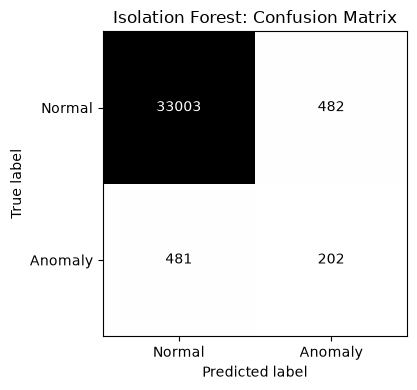

In [6]:
# 6(a). Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, iso_pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomaly"]).plot(
    ax=ax, cmap="Greys", values_format="d", colorbar=False
)
ax.set_title("Isolation Forest: Confusion Matrix")
plt.tight_layout()
plt.show()

[[32886   599]
 [  598    85]]
TN=32886  FP=599  FN=598  TP=85


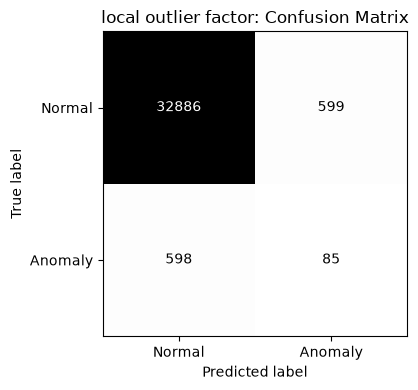

In [7]:
# 6(b). Confusion Matrix for local outlier factor
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, lof_pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomaly"]).plot(
    ax=ax, cmap="Greys", values_format="d", colorbar=False
)
ax.set_title("local outlier factor: Confusion Matrix")
plt.tight_layout()
plt.show()

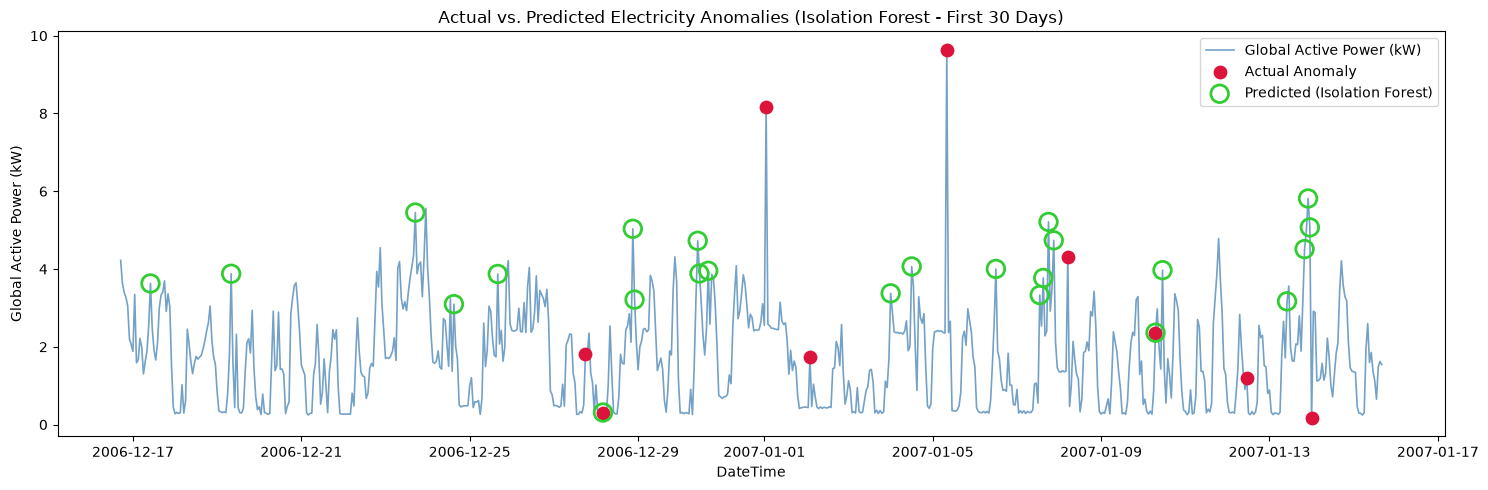

In [8]:
# 7. Visualize Actual vs. Predicted Anomalies
best_pred = iso_pred if results.loc[0, "F1-Score"] >= results.loc[1, "F1-Score"] else lof_pred
best_name = "Isolation Forest" if results.loc[0, "F1-Score"] >= results.loc[1, "F1-Score"] else "LOF"

# Plot a 30-day window containing anomalies for clear visual inspection
sample_slice = slice(0, 24 * 30)
t = data.index[sample_slice]
p = data["Global_active_power"].iloc[sample_slice]
act = y_true[sample_slice] == 1
prd = best_pred[sample_slice] == 1

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(t, p, color="steelblue", alpha=0.75, linewidth=1.2, label="Global Active Power (kW)")
ax.scatter(t[act], p[act], color="crimson", s=80, marker="o", label="Actual Anomaly", zorder=4)
ax.scatter(t[prd], p[prd], facecolors="none", edgecolors="limegreen", s=160, linewidths=2, label=f"Predicted ({best_name})", zorder=5)

ax.set_title(f"Actual vs. Predicted Electricity Anomalies ({best_name} - First 30 Days)")
ax.set_xlabel("DateTime")
ax.set_ylabel("Global Active Power (kW)")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
import joblib

joblib.dump(
    iso,
    "../Models/anomaly_detection_model.pkl"
)

['../Models/anomaly_detection_model.pkl']